In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 1. Dataset paths
path = "/home/aj/Jupyter_Notebooks/DL_Sem_7/Datasets/cats_and_dogs_filtered/"

train_dir = path + "/train"
val_dir = path + "/validation"

I0000 00:00:1793719402.594994    9498 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793719402.599099    9498 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793719402.892216    9498 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793719405.827426    9498 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
# 2. Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(160, 160),
    batch_size=32,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(160, 160),
    batch_size=32,
    label_mode="binary"
)

class_names = train_ds.class_names
print("Classes:", class_names)

# 3. Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# 4. Create transfer learning model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(160, 160, 3)),
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# 5. Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 6. Train model
model.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds
)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


E0000 00:00:1793719413.632269    9498 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Classes: ['cats', 'dogs']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5


/home/aj/.local/share/uv/tools/notebook/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 36s 546ms/step - accuracy: 0.9325 - loss: 0.1896 - val_accuracy: 0.9750 - val_loss: 0.0844
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 32s 504ms/step - accuracy: 0.9785 - loss: 0.0732 - val_accuracy: 0.9800 - val_loss: 0.0607
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 31s 499ms/step - accuracy: 0.9850 - loss: 0.0527 - val_accuracy: 0.9810 - val_loss: 0.0529
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 32s 502ms/step - accuracy: 0.9875 - loss: 0.0439 - val_accuracy: 0.9840 - val_loss: 0.0479
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 33s 523ms/step - accuracy: 0.9915 - loss: 0.0358 - val_accuracy: 0.9870 - val_loss: 0.0436


32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 334ms/step - accuracy: 0.9870 - loss: 0.0436
Validation Accuracy: 0.9869999885559082
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 637ms/step


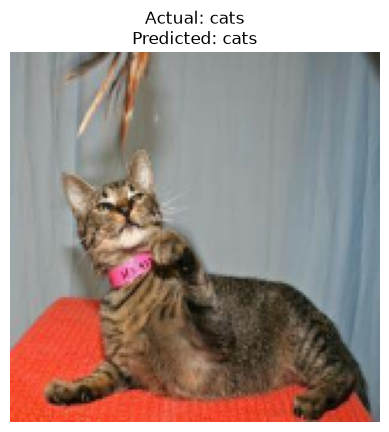

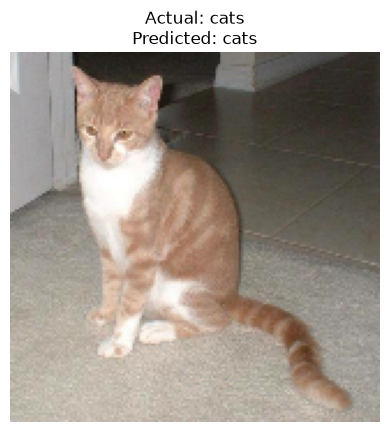

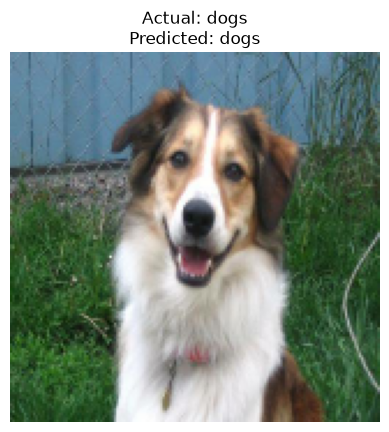

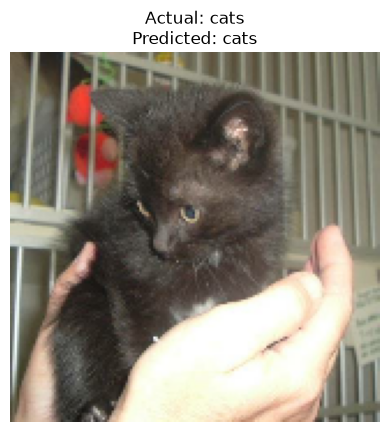

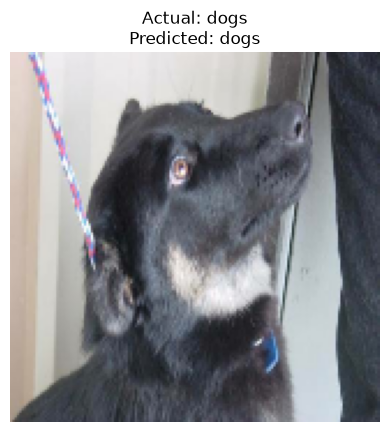

In [3]:
# 7. Evaluate model
loss, accuracy = model.evaluate(val_ds)
print("Validation Accuracy:", accuracy)

# 8. Display predictions
for images, labels in val_ds.take(1):
    predictions = model.predict(images[:5])

    for i in range(5):
        index = int(predictions[i][0] >= 0.5)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(
            "Actual: " + class_names[int(labels[i][0])] +
            "\nPredicted: " + class_names[index]
        )
        plt.axis("off")
        plt.show()